# Quantium Task 1: Chip Category Customer Analysis

**Goal:** understand who buys chips and what drives their spending, so the Category Manager (Julia) can plan the next half-year.

**Data:** 12 months of supermarket transactions (July 2018 – June 2019) plus customer segments (life stage and price tier). Sales are in **Australian dollars ($)**.

**Steps:** load and check the data → clean it → add pack size and brand → merge customer segments → analyse segments → test whether the difference is real → look at what the key segment prefers.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

DATA = Path("../data")
CHARTS = Path("../charts"); CHARTS.mkdir(exist_ok=True)
BLUE, GREY = "#2E86C1", "#B8C2CC"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6E9ED", "axes.axisbelow": True})
pd.set_option("display.float_format", "{:,.2f}".format)

## 1. Load and check the data

In [2]:
txn = pd.read_excel(DATA / "QVI_transaction_data.xlsx")
cust = pd.read_csv(DATA / "QVI_purchase_behaviour.csv")
print("Transactions:", txn.shape, "| Customers:", cust.shape)
print("Missing values:", txn.isna().sum().sum() + cust.isna().sum().sum())
txn.head()

Transactions: (264836, 8) | Customers: (72637, 3)
Missing values: 0


,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES
0,43390,1,1000,1,5,Natural Chip Compny SeaSalt175g,2,6.00
1,43599,1,1307,348,66,CCs Nacho Cheese 175g,3,6.30
2,43605,1,1343,383,61,Smiths Crinkle Cut Chips Chicken 170g,2,2.90
3,43329,2,2373,974,69,Smiths Chip Thinly S/Cream&Onion 175g,5,15.00
4,43330,2,2426,1038,108,Kettle Tortilla ChpsHny&Jlpno Chili 150g,3,13.80


`DATE` is stored as an Excel serial number (days since 30 Dec 1899), so it needs converting to a real date.

In [3]:
txn["DATE"] = pd.to_datetime("1899-12-30") + pd.to_timedelta(txn["DATE"], unit="D")
print("From", txn["DATE"].min().date(), "to", txn["DATE"].max().date(), "|", txn["DATE"].nunique(), "distinct days")
missing_days = pd.date_range(txn["DATE"].min(), txn["DATE"].max()).difference(txn["DATE"].unique())
print("Days with no transactions:", [d.date() for d in missing_days])

From 2018-07-01 to 2019-06-30 | 364 distinct days
Days with no transactions: [datetime.date(2018, 12, 25)]


Only one day of 365 is missing: **25 December**, when stores are closed, so it isn't a data problem.

## 2. Clean the data

**2.1 Product names.** Some names contain repeated spaces (e.g. `Smiths Crnkle Chip  Orgnl`), so whitespace is collapsed.

In [4]:
txn["PROD_NAME"] = txn["PROD_NAME"].str.replace(r"\s+", " ", regex=True).str.strip()

**2.2 Remove salsa.** The category is chips, but the product list includes salsa dips, so those rows are dropped.

In [5]:
is_salsa = txn["PROD_NAME"].str.lower().str.contains("salsa")
print("Salsa rows removed:", is_salsa.sum())
txn = txn[~is_salsa]

Salsa rows removed: 18094


**2.3 Outliers.** `PROD_QTY` is normally 1–5, but two transactions bought **200 packs**.

In [6]:
print(txn["PROD_QTY"].value_counts().sort_index())
txn[txn["PROD_QTY"] == 200]

PROD_QTY
1       25476
2      220070
3         408
4         371
5         415
200         2
Name: count, dtype: int64


,DATE,STORE_NBR,LYLTY_CARD_NBR,TXN_ID,PROD_NBR,PROD_NAME,PROD_QTY,TOT_SALES
69762,2018-08-19,226,226000,226201,4,Dorito Corn Chp Supreme 380g,200,650.00
69763,2019-05-20,226,226000,226210,4,Dorito Corn Chp Supreme 380g,200,650.00


In [7]:
big_buyer = txn.loc[txn["PROD_QTY"] == 200, "LYLTY_CARD_NBR"].unique()
print("Loyalty card(s):", big_buyer)
print("Other transactions by this card:", (txn["LYLTY_CARD_NBR"].isin(big_buyer) & (txn["PROD_QTY"] != 200)).sum())

Loyalty card(s): [226000]
Other transactions by this card: 0


This customer only ever bought 200 packs at a time, so it is most likely a business buying stock rather than a household. They are removed so they don't distort the customer analysis.

In [8]:
txn = txn[~txn["LYLTY_CARD_NBR"].isin(big_buyer)]
print("Rows after cleaning:", f"{len(txn):,}", "| Total sales: $" + f"{txn['TOT_SALES'].sum():,.2f}")

Rows after cleaning: 246,740 | Total sales: $1,805,177.70


## 3. New features: pack size and brand

Pack sizes range from 70 g to 380 g


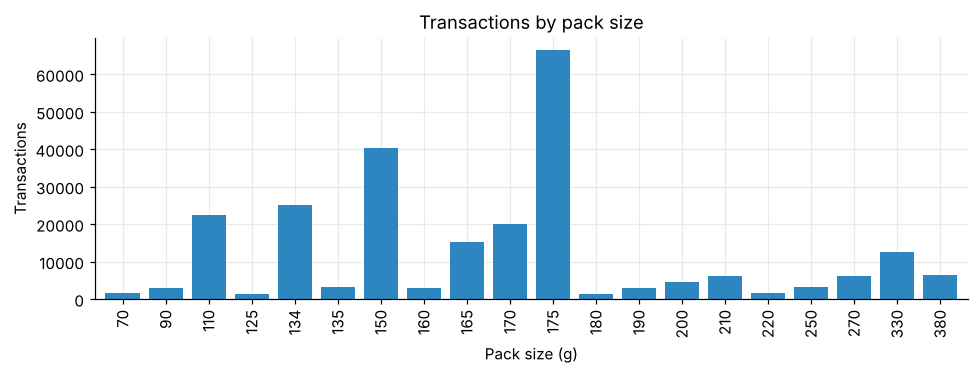

In [9]:
txn["PACK_SIZE"] = txn["PROD_NAME"].str.extract(r"(\d+)\s*[gG]", expand=False).astype(int)
print("Pack sizes range from", txn["PACK_SIZE"].min(), "g to", txn["PACK_SIZE"].max(), "g")

ax = txn["PACK_SIZE"].value_counts().sort_index().plot(kind="bar", color=BLUE, width=0.8, figsize=(9, 3.5))
ax.set(title="Transactions by pack size", xlabel="Pack size (g)", ylabel="Transactions")
plt.tight_layout(); plt.show()

The brand is the first word of the name, but some brands appear under two spellings (e.g. `Dorito` / `Doritos`, `WW` / `Woolworths`), so they are merged.

In [10]:
BRAND_FIX = {"Red": "RRD", "Dorito": "Doritos", "Infzns": "Infuzions", "Smith": "Smiths",
             "Snbts": "Sunbites", "WW": "Woolworths", "GrnWves": "Grain Waves", "Grain": "Grain Waves",
             "NCC": "Natural Chip Co", "Natural": "Natural Chip Co", "French": "French Fries",
             "Burger": "Burger Rings", "Infuzions": "Infuzions"}
txn["BRAND"] = txn["PROD_NAME"].str.split().str[0].replace(BRAND_FIX)
txn["BRAND"].value_counts()

BRAND
Kettle             41288
Smiths             30353
Doritos            25224
Pringles           25102
RRD                16321
Infuzions          14201
Thins              14075
Woolworths         11836
Cobs                9693
Tostitos            9471
Twisties            9454
Grain Waves         7740
Natural Chip Co     7469
Tyrrells            6442
Cheezels            4603
CCs                 4551
Sunbites            3008
Cheetos             2927
Burger Rings        1564
French Fries        1418
Name: count, dtype: int64

## 4. Merge customer segments

In [11]:
data = txn.merge(cust, on="LYLTY_CARD_NBR", how="left")
print("Rows:", f"{len(data):,}", "| Transactions without a customer segment:", data["LIFESTAGE"].isna().sum())
data.to_csv(DATA / "QVI_data.csv", index=False)
print("Saved cleaned data to data/QVI_data.csv for Task 2")

Rows: 246,740 | Transactions without a customer segment: 0


Saved cleaned data to data/QVI_data.csv for Task 2


Every transaction matched a customer, so no rows are lost in the merge.

## 5. Who drives chip sales?

In [12]:
seg = (data.groupby(["LIFESTAGE", "PREMIUM_CUSTOMER"])
         .agg(sales=("TOT_SALES", "sum"), customers=("LYLTY_CARD_NBR", "nunique"),
              units=("PROD_QTY", "sum"), txns=("TXN_ID", "nunique")))
seg["sales_share_%"] = seg["sales"] / seg["sales"].sum() * 100
seg["units_per_customer"] = seg["units"] / seg["customers"]
seg["price_per_unit"] = seg["sales"] / seg["units"]
seg = seg.sort_values("sales", ascending=False)
seg.round(2)

sales  customers  units   txns  \
LIFESTAGE              PREMIUM_CUSTOMER                                       
OLDER FAMILIES         Budget           156,863.75       4611  41853  21322   
YOUNG SINGLES/COUPLES  Mainstream       147,582.20       7917  36225  19482   
RETIREES               Mainstream       145,168.95       6358  37677  19878   
YOUNG FAMILIES         Budget           129,717.95       3953  34482  17629   
OLDER SINGLES/COUPLES  Budget           127,833.60       4849  32883  17078   
                       Mainstream       124,648.50       4858  32607  16958   
                       Premium          123,537.55       4682  31695  16472   
RETIREES               Budget           105,916.30       4385  26932  14147   
OLDER FAMILIES         Mainstream        96,413.55       2788  25804  13131   
RETIREES               Premium           91,296.65       3812  23266  12180   
YOUNG FAMILIES         Mainstream        86,338.25       2685  23194  11860   
MIDAGE SINGLES/COUPLES Mainstream        84,734.25       3298  21213  11034   
YOUNG FAMILIES         Premium           78,571.70       2398  20901  10701   
OLDER FAMILIES         Premium           75,242.60       2231  20239  10302   
YOUNG SINGLES/COUPLES  Budget            57,122.10       3647  15500   8547   
MIDAGE SINGLES/COUPLES Premium           54,443.85       2369  14400   7564   
YOUNG SINGLES/COUPLES  Premium           39,052.30       2480  10575   5834   
MIDAGE SINGLES/COUPLES Budget            33,345.70       1474   8883   4661   
NEW FAMILIES           Budget            20,607.45       1087   5241   2813   
                       Mainstream        15,979.70        830   4060   2181   
                       Premium           10,760.80        575   2769   1483   

                                         sales_share_%  units_per_customer  \
LIFESTAGE              PREMIUM_CUSTOMER                                      
OLDER FAMILIES         Budget                     8.69                9.08   
YOUNG SINGLES/COUPLES  Mainstream                 8.18                4.58   
RETIREES               Mainstream                 8.04                5.93   
YOUNG FAMILIES         Budget                     7.19                8.72   
OLDER SINGLES/COUPLES  Budget                     7.08                6.78   
                       Mainstream                 6.91                6.71   
                       Premium                    6.84                6.77   
RETIREES               Budget                     5.87                6.14   
OLDER FAMILIES         Mainstream                 5.34                9.26   
RETIREES               Premium                    5.06                6.10   
YOUNG FAMILIES         Mainstream                 4.78                8.64   
MIDAGE SINGLES/COUPLES Mainstream                 4.69                6.43   
YOUNG FAMILIES         Premium                    4.35                8.72   
OLDER FAMILIES         Premium                    4.17                9.07   
YOUNG SINGLES/COUPLES  Budget                     3.16                4.25   
MIDAGE SINGLES/COUPLES Premium                    3.02                6.08   
YOUNG SINGLES/COUPLES  Premium                    2.16                4.26   
MIDAGE SINGLES/COUPLES Budget                     1.85                6.03   
NEW FAMILIES           Budget                     1.14                4.82   
                       Mainstream                 0.89                4.89   
                       Premium                    0.60                4.82   

                                         price_per_unit  
LIFESTAGE              PREMIUM_CUSTOMER                  
OLDER FAMILIES         Budget                      3.75  
YOUNG SINGLES/COUPLES  Mainstream                  4.07  
RETIREES               Mainstream                  3.85  
YOUNG FAMILIES         Budget                      3.76  
OLDER SINGLES/COUPLES  Budget                      3.89  
                       Mai

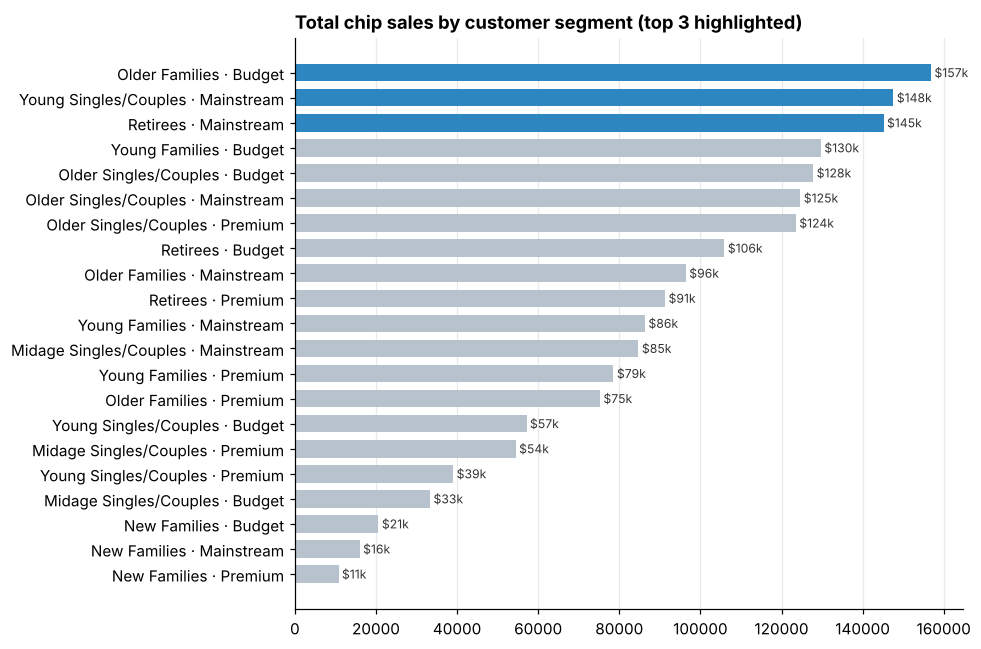

In [13]:
def seg_bar(col, title, fmt, fname, top=3):
    s = seg[col].sort_values()
    labels = [f"{l.title()} · {p}" for l, p in s.index]
    colours = [BLUE if i >= len(s) - top else GREY for i in range(len(s))]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(labels, s.values, color=colours, height=0.7)
    for i, v in enumerate(s.values):
        ax.text(v, i, " " + fmt(v), va="center", fontsize=8, color="#333")
    ax.set_title(title, loc="left", fontweight="bold"); ax.grid(axis="y", visible=False)
    plt.tight_layout(); fig.savefig(CHARTS / fname, bbox_inches="tight"); plt.show()

seg_bar("sales", "Total chip sales by customer segment (top 3 highlighted)", lambda v: f"${v/1000:,.0f}k", "t1_sales_by_segment.png")

Sales come mainly from **Budget older families**, **Mainstream young singles/couples** and **Mainstream retirees**. The next charts show *why*: is it because there are more of these customers, or because each one buys more?

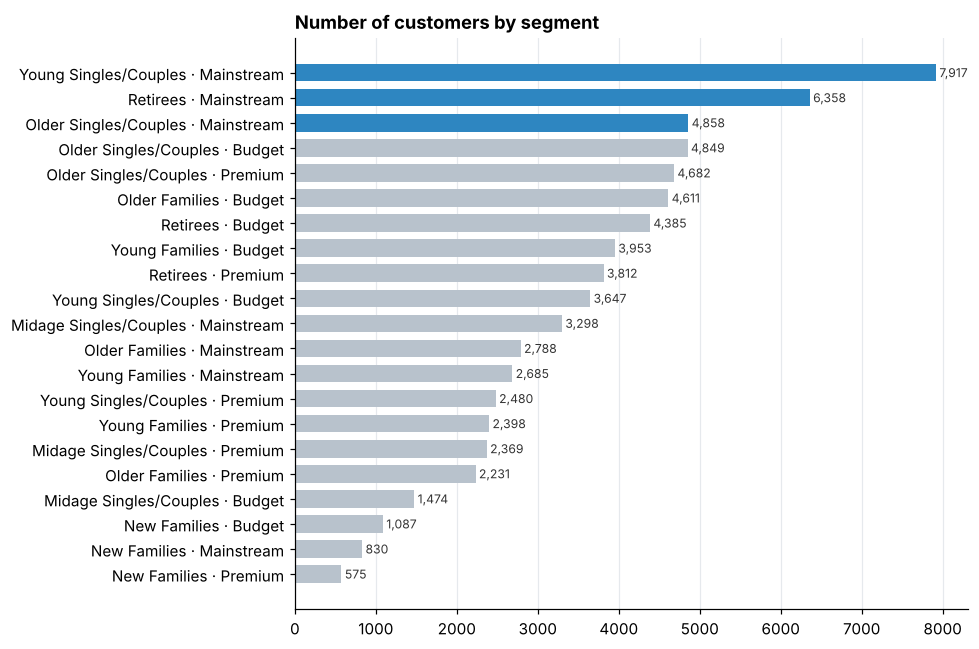

In [14]:
seg_bar("customers", "Number of customers by segment", lambda v: f"{v:,.0f}", "t1_customers_by_segment.png")

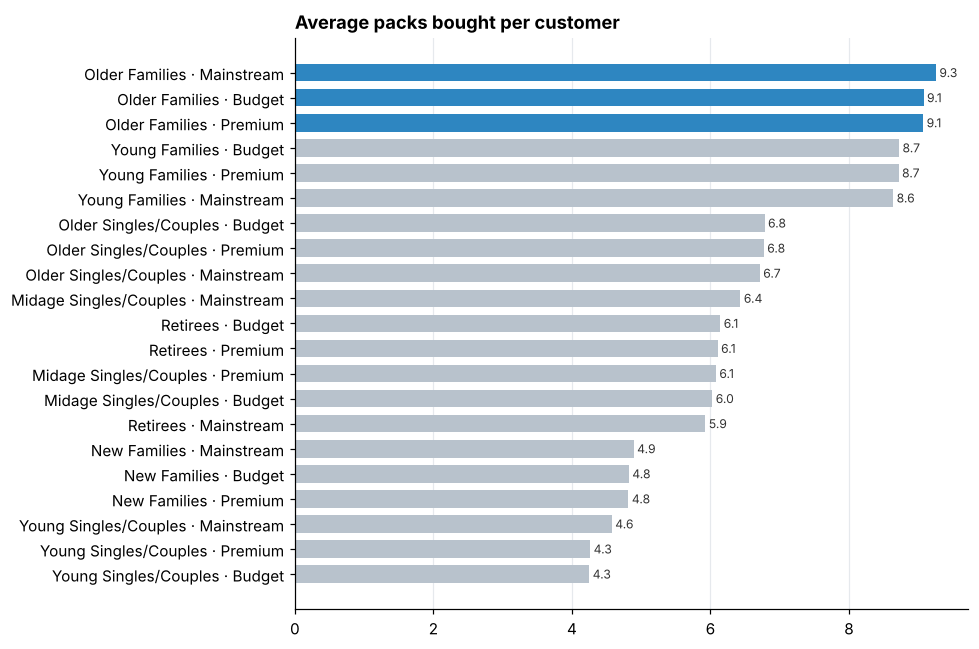

In [15]:
seg_bar("units_per_customer", "Average packs bought per customer", lambda v: f"{v:.1f}", "t1_units_per_customer.png")

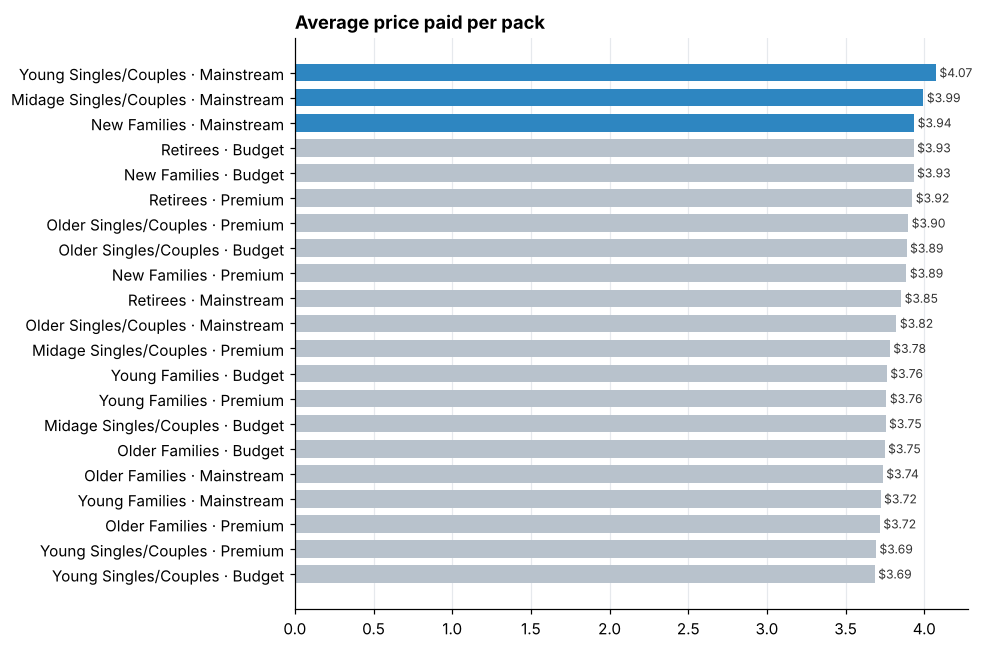

In [16]:
seg_bar("price_per_unit", "Average price paid per pack", lambda v: f"${v:.2f}", "t1_price_per_unit.png")

**What the segment charts show:**
- **Budget older families** are the biggest segment by sales (8.7% of the total). That's driven by how much each customer buys: families buy about **9 packs each** over the year, double young singles/couples.
- **Mainstream young singles/couples** (7,917 customers) and **Mainstream retirees** (6,358) are big because there are **so many of them**. Each buys fewer packs.
- **Mainstream young and mid-age singles/couples pay the most per pack** (\$4.07 and \$3.99), which suggests they treat chips as an impulse buy rather than a planned grocery item.

## 6. Is the price difference real? (t-test)

Mainstream young and mid-age singles/couples seem to pay more per pack than Budget and Premium customers in the same life stages. A Welch t-test checks whether that difference could be due to chance.

In [17]:
data["PRICE_PER_UNIT"] = data["TOT_SALES"] / data["PROD_QTY"]
young_mid = data["LIFESTAGE"].isin(["YOUNG SINGLES/COUPLES", "MIDAGE SINGLES/COUPLES"])
mainstream = data.loc[young_mid & (data["PREMIUM_CUSTOMER"] == "Mainstream"), "PRICE_PER_UNIT"]
others = data.loc[young_mid & (data["PREMIUM_CUSTOMER"] != "Mainstream"), "PRICE_PER_UNIT"]
t, p = stats.ttest_ind(mainstream, others, equal_var=False, alternative="greater")
print(f"Mainstream: ${mainstream.mean():.3f} per pack | Budget + Premium: ${others.mean():.3f} per pack")
print(f"t = {t:.1f}, p = {p:.2e}")

Mainstream: $4.040 per pack | Budget + Premium: $3.706 per pack
t = 37.6, p = 3.48e-306


The p-value is effectively zero, so the difference is **statistically significant**: Mainstream young and mid-age singles/couples really do pay more per pack than Budget and Premium customers in the same life stages.

## 7. What does the key segment prefer?

**Affinity** compares how often Mainstream young singles/couples buy a brand or pack size with how often everyone else does. A value above 1 means they buy it more than the rest of the market.

In [18]:
target = (data["LIFESTAGE"] == "YOUNG SINGLES/COUPLES") & (data["PREMIUM_CUSTOMER"] == "Mainstream")

def affinity(col):
    t_share = data.loc[target].groupby(col)["PROD_QTY"].sum() / data.loc[target, "PROD_QTY"].sum()
    o_share = data.loc[~target].groupby(col)["PROD_QTY"].sum() / data.loc[~target, "PROD_QTY"].sum()
    return (pd.DataFrame({"target_share": t_share, "other_share": o_share})
              .assign(affinity=lambda d: d["target_share"] / d["other_share"])
              .sort_values("affinity", ascending=False))

brand_aff = affinity("BRAND"); brand_aff.round(3)

,target_share,other_share,affinity
BRAND,,,
Tyrrells,0.03,0.03,1.23
Twisties,0.05,0.04,1.22
Doritos,0.12,0.10,1.22
Kettle,0.20,0.17,1.20
Tostitos,0.04,0.04,1.20
Pringles,0.12,0.10,1.19
Cobs,0.04,0.04,1.14
Infuzions,0.07,0.06,1.13
Thins,0.06,0.06,1.06


In [19]:
pack_aff = affinity("PACK_SIZE"); pack_aff.round(3)

,target_share,other_share,affinity
PACK_SIZE,,,
270,0.03,0.03,1.27
380,0.03,0.03,1.26
330,0.06,0.05,1.22
134,0.12,0.10,1.19
110,0.11,0.09,1.18
210,0.03,0.03,1.16
135,0.01,0.01,1.13
250,0.01,0.01,1.12
170,0.08,0.08,1.00


In [20]:
print("Brands of 270g packs:", data.loc[data["PACK_SIZE"] == 270, "BRAND"].unique())

Brands of 270g packs: ['Twisties']


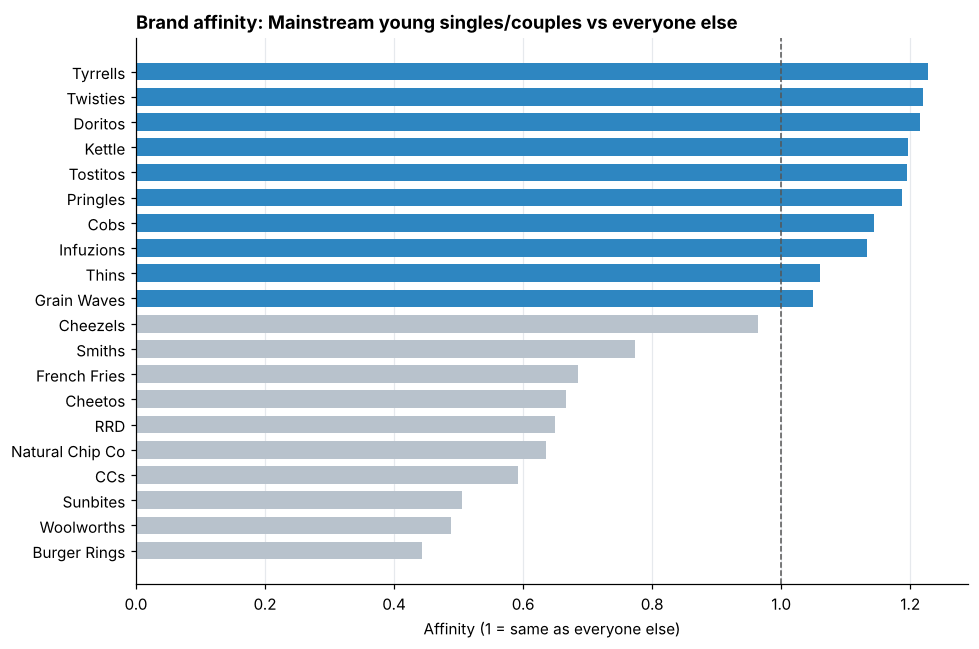

In [21]:
s = brand_aff["affinity"].sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(s.index, s.values, color=[BLUE if v > 1 else GREY for v in s.values], height=0.7)
ax.axvline(1, color="#555", lw=1, ls="--")
ax.set_title("Brand affinity: Mainstream young singles/couples vs everyone else", loc="left", fontweight="bold")
ax.set_xlabel("Affinity (1 = same as everyone else)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); fig.savefig(CHARTS / "t1_brand_affinity.png", bbox_inches="tight"); plt.show()

Compared with everyone else, Mainstream young singles/couples are:
- **about 20% more likely** to buy Tyrrells, Twisties, Doritos, Kettle, Tostitos and Pringles
- **about 50% less likely** to buy Woolworths own brand, Burger Rings and Sunbites
- **about 27% more likely** to buy 270g packs, which only Twisties sells. The preference for this pack size may just be a preference for Twisties.

## 8. Summary and recommendations for Julia

**Findings**
1. Sales are driven by **Budget older families** (they buy the most packs each), and by **Mainstream young singles/couples** and **Mainstream retirees** (there are many of them).
2. **Mainstream young and mid-age singles/couples pay significantly more per pack** (t-test, p < 0.001), which is consistent with impulse buying.
3. Mainstream young singles/couples lean towards **premium brands** (Tyrrells, Kettle, Doritos, Pringles) and **larger packs**.

**Recommendations**
- Put **Tyrrells, Twisties, Doritos, Kettle and Pringles** in prominent, impulse-friendly spots (end-of-aisle, near the till) in stores where young singles and couples shop, since this segment pays more per pack.
- Keep **family-size packs** well stocked and promoted for older families, the biggest sales segment.
- Test this placement in a few stores first and measure it, which is exactly what Task 2 does.